# Comparing Simple and Multiple Linear Regression

This beginner-friendly notebook creates a reproducible synthetic dataset, saves and reloads it as a CSV, then compares simple linear regression (SLR) with multiple linear regression (MLR). The continuous outcome is a fictional exam score; these data do not describe real students.

**SLR** uses one input feature. **MLR** uses two or more input features. Both models predict the same continuous outcome.

## 1. Import libraries

Install the packages listed in `requirements.txt` into your environment before running the notebook.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
N_OBSERVATIONS = 5_000
DATA_PATH = Path.cwd() / "regression_data.csv"


## 2. Generate and save the synthetic dataset

The outcome is constructed from the predictors plus random noise, creating a learnable relationship. The fixed seed makes the generated data reproducible.

In [2]:
rng = np.random.default_rng(RANDOM_SEED)

experience_years = rng.uniform(0, 10, size=N_OBSERVATIONS)
study_hours = rng.uniform(0, 20, size=N_OBSERVATIONS)
attendance_pct = rng.uniform(60, 100, size=N_OBSERVATIONS)
prior_score = rng.uniform(40, 100, size=N_OBSERVATIONS)
tutoring_sessions = rng.integers(0, 9, size=N_OBSERVATIONS)
sleep_hours = rng.uniform(4, 10, size=N_OBSERVATIONS)
noise = rng.normal(0, 8, size=N_OBSERVATIONS)

exam_score = (
    15
    + 1.2 * experience_years
    + 2.0 * study_hours
    + 0.25 * attendance_pct
    + 0.35 * prior_score
    + 2.0 * tutoring_sessions
    + 1.5 * sleep_hours
    + noise
)

data = pd.DataFrame(
    {
        "experience_years": experience_years,
        "study_hours_per_week": study_hours,
        "attendance_pct": attendance_pct,
        "prior_score": prior_score,
        "tutoring_sessions_per_month": tutoring_sessions,
        "sleep_hours_per_night": sleep_hours,
        "exam_score": exam_score,
    }
)
data.to_csv(DATA_PATH, index=False)
print(f"Saved {len(data):,} observations to {DATA_PATH.resolve()}")

Saved 5,000 observations to C:\Users\LUDACRIS\Desktop\Emmanuel Asante\etornam_quiz_2\regression_data.csv


## 3. Load and inspect the CSV

Reloading the file demonstrates how the saved dataset can be used in a separate analysis.

In [3]:
data = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (5000, 7)


,experience_years,study_hours_per_week,attendance_pct,prior_score,tutoring_sessions_per_month,sleep_hours_per_night,exam_score
0,7.739560,4.362984,88.829135,60.853299,8,7.201175,110.547592
1,4.388784,13.258554,88.449510,46.168435,6,5.226286,108.544673
2,8.585979,15.337230,68.107801,58.124108,1,4.526981,114.420037
3,6.973680,3.332723,61.466216,88.402381,8,8.398147,109.045113
4,0.941773,0.877166,72.151981,69.608772,8,6.304772,98.301889


## 4. Split into training and testing data

The test set is held back from training. Both models use the same split so their test metrics can be compared fairly.

In [4]:
target = "exam_score"
slr_feature = ["experience_years"]
mlr_features = [
    "experience_years",
    "study_hours_per_week",
    "attendance_pct",
    "prior_score",
    "tutoring_sessions_per_month",
    "sleep_hours_per_night",
]

train_data, test_data = train_test_split(
    data, test_size=0.20, random_state=RANDOM_SEED
)
y_train = train_data[target]
y_test = test_data[target]
print(f"Training observations: {len(train_data):,}")
print(f"Testing observations: {len(test_data):,}")

Training observations: 4,000
Testing observations: 1,000


## 5. Train the simple linear regression model

This model uses only `experience_years` (years of prior learning experience) to predict exam score.

In [5]:
slr_model = LinearRegression()
slr_model.fit(train_data[slr_feature], y_train)
slr_predictions = slr_model.predict(test_data[slr_feature])
print(f"Learned coefficient: {slr_model.coef_[0]:.3f}")
print(f"Learned intercept: {slr_model.intercept_:.3f}")

Learned coefficient: 1.363
Learned intercept: 97.428


## 6. Train the multiple linear regression model

This model uses all six input features together to predict exam score.

In [6]:
mlr_model = LinearRegression()
mlr_model.fit(train_data[mlr_features], y_train)
mlr_predictions = mlr_model.predict(test_data[mlr_features])
pd.Series(mlr_model.coef_, index=mlr_features, name="coefficient")

experience_years               1.178642
study_hours_per_week           1.964010
attendance_pct                 0.246601
prior_score                    0.347064
tutoring_sessions_per_month    2.004153
sleep_hours_per_night          1.496380
Name: coefficient, dtype: float64

## 7. Compare test-set metrics

- **MSE (Mean Squared Error):** the average squared prediction error. Squaring emphasizes larger errors, so lower is better.
- **MAE (Mean Absolute Error):** the average absolute prediction error, in exam-score points. Lower is better.
- **RMSE (Root Mean Squared Error):** the square root of MSE, expressed in exam-score points. Lower is better, and larger errors have more influence.
- **R² (coefficient of determination):** the proportion of test-outcome variation explained by the model. A value closer to 1 indicates a better fit; it can be negative when predictions are worse than predicting the test mean.

In [7]:
def calculate_metrics(actual, predicted):
    return {
        "MSE": mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": root_mean_squared_error(actual, predicted),
        "R2": r2_score(actual, predicted),
    }


metrics = pd.DataFrame(
    {
        "Simple linear regression": calculate_metrics(y_test, slr_predictions),
        "Multiple linear regression": calculate_metrics(y_test, mlr_predictions),
    }
).T
metrics

,MSE,MAE,RMSE,R2
Simple linear regression,277.457587,13.505006,16.657058,0.042138
Multiple linear regression,60.910426,6.206673,7.804513,0.789720


## 8. Plot 10 test predictions and their residuals

Each plot compares actual and predicted scores for the same 10 test observations. The vertical segment shows the residual (`actual - predicted`); its label reports the signed value in score points.

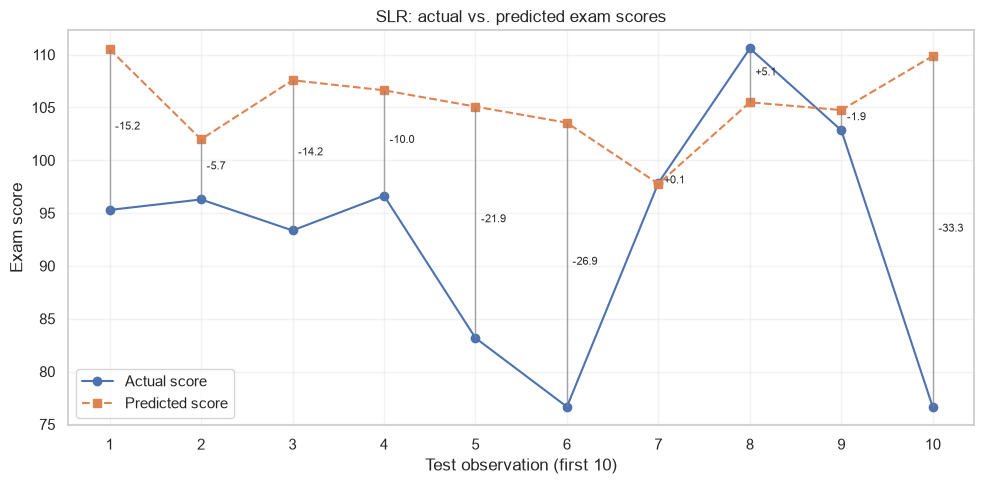

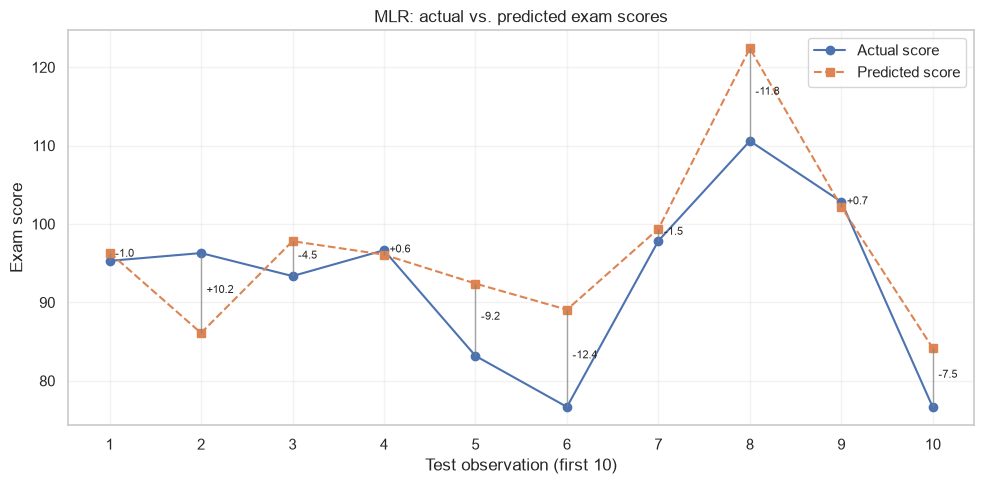

In [8]:
def plot_predictions(actual, predicted, title):
    actual_values = np.asarray(actual)[:10]
    predicted_values = np.asarray(predicted)[:10]
    residuals = actual_values - predicted_values
    observation_numbers = np.arange(1, len(actual_values) + 1)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(observation_numbers, actual_values, "o-", label="Actual score")
    ax.plot(observation_numbers, predicted_values, "s--", label="Predicted score")
    for x, actual_value, predicted_value, residual in zip(
        observation_numbers, actual_values, predicted_values, residuals
    ):
        ax.vlines(x, min(actual_value, predicted_value), max(actual_value, predicted_value),
                  color="gray", alpha=0.7, linewidth=1)
        ax.annotate(f"{residual:+.1f}", (x, (actual_value + predicted_value) / 2),
                    xytext=(4, 0), textcoords="offset points", fontsize=8)

    ax.set_title(title)
    ax.set_xlabel("Test observation (first 10)")
    ax.set_ylabel("Exam score")
    ax.set_xticks(observation_numbers)
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()


plot_predictions(y_test, slr_predictions, "SLR: actual vs. predicted exam scores")
plot_predictions(y_test, mlr_predictions, "MLR: actual vs. predicted exam scores")

## 9. Interpret the residuals and compare the models

A **positive residual** means the actual score was higher than the prediction, so the model underpredicted. A **negative residual** means the model overpredicted. The absolute residual size is the prediction error in score points; shorter segments indicate more accurate predictions for those observations.

Compare the two models using the test-set metrics above. MLR may perform better because it uses more of the features that generated the outcome, but the result should be judged on held-out test data rather than training fit. These examples illustrate prediction on synthetic data and do not establish causal effects.